# Hệ thống gợi ý phim bằng KNN – so sánh nhiều bộ MovieLens
Đặt các thư mục dữ liệu (ml-100k, ml-1m, ml-latest-small...) cạnh `recsys.py` hoặc trong `data/`. Notebook tự tìm và chạy **tất cả** các bộ tìm thấy. Chạy Run All.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import recsys

DATASETS = "all"   # "all" = mọi bộ tìm thấy | hoặc danh sách, vd ["ml-100k", "ml-1m"]
KS = [5, 10, 20, 50, 100, 200]
names = list(recsys.list_datasets()) if DATASETS == "all" else DATASETS
print("Sẽ chạy trên:", names)

Sẽ chạy trên: ['ml-100k', 'ml-1m']


## 1. Khám phá dữ liệu (mỗi bộ một cột)

Các bộ dữ liệu tìm thấy: ['ml-100k', 'ml-1m'] | đang dùng: ml-100k (muốn chọn bộ khác: DATASET = tên thư mục)
Dùng dữ liệu tại: D:\SourceCode\Khai Thác Dữ Liệu\files\data\ml-100k (định dạng 100k)
Các bộ dữ liệu tìm thấy: ['ml-100k', 'ml-1m'] | đang dùng: ml-1m (muốn chọn bộ khác: DATASET = tên thư mục)
Dùng dữ liệu tại: D:\SourceCode\Khai Thác Dữ Liệu\files\data\ml-1m (định dạng dat)


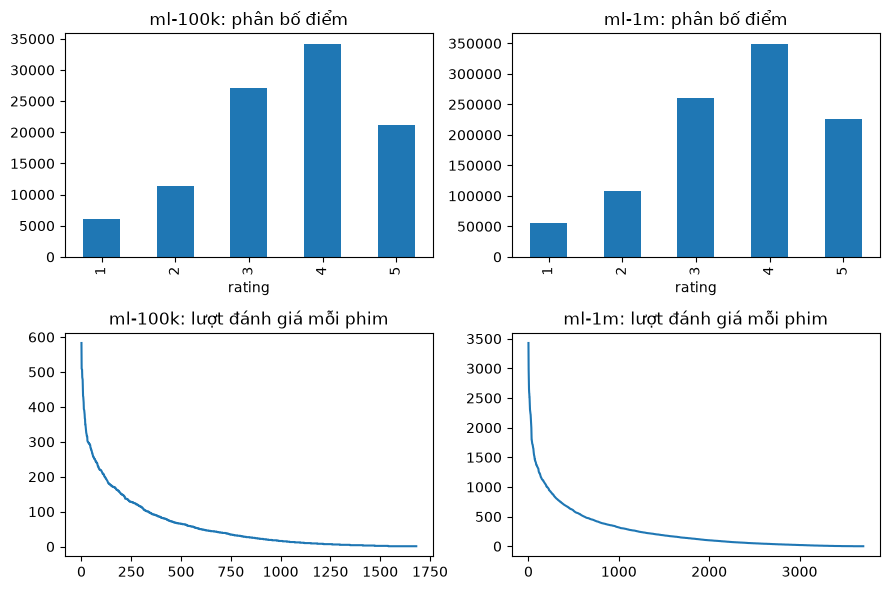

In [2]:
fig, axes = plt.subplots(2, len(names), figsize=(4.5 * len(names), 6), squeeze=False)
for j, n in enumerate(names):
    ratings, movies = recsys.load_cached(n)
    ratings.rating.value_counts().sort_index().plot.bar(ax=axes[0][j], title=f"{n}: phân bố điểm")
    ratings.groupby("item").size().sort_values(ascending=False).reset_index(drop=True).plot(
        ax=axes[1][j], title=f"{n}: lượt đánh giá mỗi phim")
plt.tight_layout(); plt.show()

## 2. Chạy thí nghiệm trên tất cả bộ dữ liệu
Mỗi bộ: chia train/test 80/20, baseline (điểm TB phim / độ phổ biến), rồi KNN Item/User với các K. Bộ 1M có thể mất vài phút.

In [3]:
res, info = recsys.run_experiments(names, ks=KS, shrink=10)
display(info)

[ml-100k] item K=5   RMSE=1.0470 P@10=0.1877 (0.3s)
[ml-100k] item K=10  RMSE=1.0084 P@10=0.1959 (0.1s)
[ml-100k] item K=20  RMSE=0.9678 P@10=0.1986 (0.3s)
[ml-100k] item K=50  RMSE=0.9335 P@10=0.1983 (0.1s)
[ml-100k] item K=100 RMSE=0.9198 P@10=0.1934 (0.3s)
[ml-100k] item K=200 RMSE=0.9150 P@10=0.1876 (0.1s)
[ml-100k] user K=5   RMSE=1.0672 P@10=0.1660 (0.1s)
[ml-100k] user K=10  RMSE=1.0296 P@10=0.1918 (0.1s)
[ml-100k] user K=20  RMSE=0.9961 P@10=0.2125 (0.1s)
[ml-100k] user K=50  RMSE=0.9589 P@10=0.2210 (0.1s)
[ml-100k] user K=100 RMSE=0.9422 P@10=0.2203 (0.1s)
[ml-100k] user K=200 RMSE=0.9361 P@10=0.2120 (0.1s)
[ml-1m] item K=5   RMSE=0.9786 P@10=0.2030 (2.5s)
[ml-1m] item K=10  RMSE=0.9436 P@10=0.2119 (2.5s)
[ml-1m] item K=20  RMSE=0.9111 P@10=0.2190 (2.6s)
[ml-1m] item K=50  RMSE=0.8829 P@10=0.2215 (2.8s)
[ml-1m] item K=100 RMSE=0.8726 P@10=0.2165 (2.7s)
[ml-1m] item K=200 RMSE=0.8689 P@10=0.2121 (2.8s)
[ml-1m] user K=5   RMSE=1.0393 P@10=0.1611 (3.6s)
[ml-1m] user K=10  RMSE=1.

,dataset,users,movies,ratings,sparsity
0,ml-100k,943,1682,100000,0.9370
1,ml-1m,6040,3883,1000209,0.9574


In [4]:
res.round(4)

,dataset,mode,K,MAE,RMSE,P@10,R@10,fit_sec
0,ml-100k,baseline,0,0.8123,1.0210,0.1354,0.1371,0.0000
1,ml-100k,item,5,0.8024,1.0470,0.1877,0.1831,0.3440
2,ml-100k,item,10,0.7742,1.0084,0.1959,0.1871,0.1155
3,ml-100k,item,20,0.7456,0.9678,0.1986,0.1908,0.3220
4,ml-100k,item,50,0.7248,0.9335,0.1983,0.1916,0.1199
5,ml-100k,item,100,0.7171,0.9198,0.1934,0.1868,0.3118
6,ml-100k,item,200,0.7147,0.9150,0.1876,0.1776,0.1224
7,ml-100k,user,5,0.8242,1.0672,0.1660,0.1704,0.1443
8,ml-100k,user,10,0.7944,1.0296,0.1918,0.1981,0.0682
9,ml-100k,user,20,0.7689,0.9961,0.2125,0.2257,0.0701


### Cấu hình tốt nhất mỗi bộ (RMSE thấp nhất) so với baseline

In [5]:
knn = res[res["mode"] != "baseline"]
best = knn.loc[knn.groupby(["dataset", "mode"]).RMSE.idxmin()]
pd.concat([res[res["mode"] == "baseline"], best]).sort_values(["dataset", "mode"]).round(4)

,dataset,mode,K,MAE,RMSE,P@10,R@10,fit_sec
0,ml-100k,baseline,0,0.8123,1.0210,0.1354,0.1371,0.0000
6,ml-100k,item,200,0.7147,0.9150,0.1876,0.1776,0.1224
12,ml-100k,user,200,0.7299,0.9361,0.2120,0.2142,0.0763
13,ml-1m,baseline,0,0.7852,0.9824,0.1479,0.0860,0.0000
19,ml-1m,item,200,0.6795,0.8689,0.2121,0.1374,2.8415
25,ml-1m,user,200,0.7011,0.9030,0.2230,0.1508,3.4627


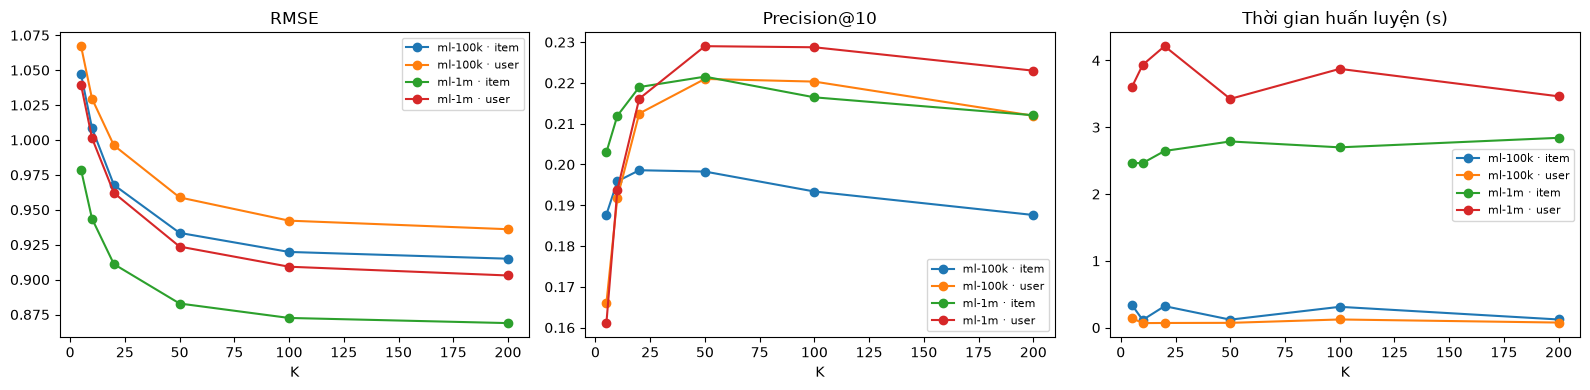

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for (ds, mode), g in knn.groupby(["dataset", "mode"]):
    for ax, col in zip(axes, ["RMSE", "P@10", "fit_sec"]):
        ax.plot(g.K, g[col], marker="o", label=f"{ds} · {mode}")
for ax, t in zip(axes, ["RMSE", "Precision@10", "Thời gian huấn luyện (s)"]):
    ax.set_title(t); ax.set_xlabel("K"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 3. Ảnh hưởng của shrinkage (K=20, item-based) trên từng bộ

In [7]:
abl = []
for s in [0, 10, 25, 50, 100]:
    r, _ = recsys.run_experiments(names, ks=[20], modes=["item"], shrink=s, quiet=True)
    abl.append(r[r["mode"] == "item"].assign(shrink=s))
pd.concat(abl).pivot(index="shrink", columns="dataset", values="RMSE").round(4)

dataset,ml-100k,ml-1m
shrink,,
0,1.0098,0.9264
10,0.9678,0.9111
25,0.9628,0.9071
50,0.9589,0.9047
100,0.9574,0.9032


## 4. Ví dụ gợi ý (trên từng bộ dữ liệu)

In [8]:
for n in names:
    ratings, movies = recsys.load_cached(n)
    n_u = int(ratings.user.max()) + 1
    model = recsys.KNNRecommender(20, "item", shrink=10).fit(recsys.to_matrix(ratings, n_u, len(movies)))
    idx, pred = model.recommend(0, 5)
    print(f"=== {n}: gợi ý cho user đầu tiên ===")
    display(movies.loc[idx, ["title", "genres"]].assign(pred=pred.round(2)))
    hit = movies.index[movies.title.str.contains("Toy Story", regex=False)]
    if len(hit):
        idx, sim = model.similar_items(hit[0], 5)
        print("Phim giống:", movies.title[hit[0]])
        display(movies.loc[idx, ["title", "genres"]].assign(sim=sim.round(3)))

=== ml-100k: gợi ý cho user đầu tiên ===


,title,genres,pred
650,Glory (1989),Action|Drama|War,4.44
317,Schindler's List (1993),Drama|War,4.86
356,One Flew Over the Cuckoo's Nest (1975),Drama,4.46
426,To Kill a Mockingbird (1962),Drama,4.68
479,North by Northwest (1959),Comedy|Thriller,4.72


Phim giống: Toy Story (1995)


,title,genres,sim
173,Raiders of the Lost Ark (1981),Action|Adventure,0.262
49,Star Wars (1977),Action|Adventure|Romance|Sci-Fi|War,0.229
587,Beauty and the Beast (1991),Animation|Children's|Musical,0.227
27,Apollo 13 (1995),Action|Drama|Thriller,0.218
94,Aladdin (1992),Animation|Children's|Comedy|Musical,0.205


=== ml-1m: gợi ý cho user đầu tiên ===


,title,genres,pred
2012,"Little Mermaid, The (1989)",Animation|Children's|Comedy|Musical|Romance,4.35
352,Forrest Gump (1994),Comedy|Romance|War,4.60
589,"Silence of the Lambs, The (1991)",Drama|Thriller,4.46
1180,Raiders of the Lost Ark (1981),Action|Adventure,4.42
360,"Lion King, The (1994)",Animation|Children's|Musical,4.30


Phim giống: Toy Story (1995)


,title,genres,sim
3045,Toy Story 2 (1999),Animation|Children's|Comedy,0.498
1180,Raiders of the Lost Ark (1981),Action|Adventure,0.308
2286,"Bug's Life, A (1998)",Animation|Children's|Comedy,0.299
315,"Shawshank Redemption, The (1994)",Drama,0.285
1178,Star Wars: Episode V - The Empire Strikes Back...,Action|Adventure|Drama|Sci-Fi|War,0.284


## 5. Phân tích & kết luận (điền theo số liệu ở bảng trên)
**So sánh giữa các bộ dữ liệu:** bộ lớn hơn (1M) có độ thưa thấp hơn nên KNN thường chính xác hơn (RMSE thấp hơn), nhưng thời gian và bộ nhớ tăng mạnh. Ghi lại K tối ưu của từng bộ: K tối ưu có thay đổi theo kích thước dữ liệu không?

**Ưu điểm:** dễ hiểu, giải thích được ("giống phim X bạn đã thích"), item-based ổn định.

**Hạn chế:** dữ liệu thưa, cold-start, bộ nhớ O(n²) cho ma trận tương đồng (không mở rộng tới 10M/25M), thiên lệch phổ biến khi xếp hạng theo điểm dự đoán.

**Ảnh hưởng của K:** K nhỏ → nhiễu; K lớn → làm mịn quá mức, thời gian tăng.

**Cách cải thiện:** shrinkage, chuẩn hoá theo user/item (đã dùng), content-based (thể loại), matrix factorization, ANN (FAISS), ma trận thưa, đánh giá theo thời gian.